In [154]:
# Section 1: Reduced Model (FitzHugh-Nagumo)
"""
FitzHugh-Nagumo (FHN) model — a 2-variable reduction of Hodgkin-Huxley.


HH's 4 variables (V, m, h, n) are hard to visualize and
analyze directly. FitzHugh (1961) noticed that m relaxes so much faster
than the other variables that you can treat it as instantaneous, and that
h and n move roughly oppositely and can be lumped into one "recovery"
variable w. That leaves 2 variables — small enough to draw an actual phase
portrait.


    dv/dt = v - v^3/3 - w + I        (v: fast "voltage-like" variable)
    dw/dt = eps * (v + a - b*w)      (w: slow "recovery" variable)


v and w here are dimensionless and NOT literally in mV — they capture the
same qualitative excitable behavior as HH's V and (h,n)-combination, not
the exact biophysical scale. That's the tradeoff for analytical tractability.


Standard parameters (FitzHugh 1961): a=0.7, b=0.8, eps=0.08
"""


A_DEFAULT = 0.7
B_DEFAULT = 0.8
EPS_DEFAULT = 0.08

import numpy as np

def fhn_derivatives(state, t, I_func, a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT):
    """
    Parameters
    ----------
    state = [v, w]
    t : float, current time in ms
    I_func : callable, I_func(t) -> injected current (constant is fine —
             pass e.g. `lambda t: 0.5` for a fixed-current bifurcation study)
             Matches the generic deriv_func(state, t) interface after currying I_func,
    a, b, eps — henomenological parameters of the FitzHugh-Nagumo model.


    Returns
    -------
    np.ndarray, d(state)/dt
    """


    v = state[0]
    w = state[1]
    dvdt = v - (v**3)/3 - w + I_func(t)
    dwdt = eps * (v + a - b*w)    
    return np.array([dvdt, dwdt])



def v_nullcline(v, I):
    """w as a function of v where dv/dt = 0."""
    w = v - (v**3)/3 + I
    return w



def w_nullcline(v, a=A_DEFAULT, b=B_DEFAULT):
    """w as a function of v where dw/dt = 0. (This one's a straight line.)"""
    w = (v + a) / b
    return w



def find_fixed_point(I, a=A_DEFAULT, b=B_DEFAULT):
    """
    Solve for the fixed point (v*, w*) where BOTH nullclines intersect.


    Substituting the w-nullcline (affine in v) into the v-nullcline gives a
    CUBIC polynomial in v alone — solvable exactly with numpy.roots, no
    iterative root-finder needed. This is a nice concrete use of
    linear algebra background: numpy.roots itself works by finding the
    eigenvalues of the polynomial's companion matrix.


    Derivation: v - v^3/3 + I = (v + a)/b
        => -(1/3) v^3 + (1 - 1/b) v + (I - a/b) = 0


    Returns (v_star, w_star) for the (unique, for standard parameters)
    real root. Raises ValueError if no real root is found (shouldn't happen for
    typical a, b, I ranges — if it does, that's worth investigating,
    not silently working around).
    """

    v_starall = np.roots([-(1/3), 0,(1 - 1/b), (I - a/b)])
    v_stararray = v_starall[np.isreal(v_starall)].real
    if len(v_stararray) != 1:
        raise ValueError("There are either more than 1 or less than 1 real root!!")
    v_star = v_stararray[0]
    w_star = (v_star + a) / b

    return v_star, w_star



def jacobian_eigenvalues(v_star, a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT):
    """
    Linearize the system around the fixed point and return its eigenvalues.


    Jacobian:
        J = [[df1/dv, df1/dw],   = [[1 - v*^2,   -1  ],
             [df2/dv, df2/dw]]     [eps,       -eps*b]]


    Eigenvalue signs tell you the fixed point's stability:
        - both real parts negative -> stable
        - either real part positive -> unstable
        - complex with real part crossing zero as a parameter varies
          -> Hopf bifurcation (birth of a limit cycle / sustained
          oscillation) — this is the mechanism behind repetitive firing.


    Returns a length-2 complex numpy array of eigenvalues.
    """
    J = [[1 - v_star**2,   -1  ],
        [eps,            -eps*b]]

    eigenvalues = np.linalg.eigvals(J)
    return eigenvalues
    



In [151]:
# Section 1.1: Write Tests
"""
Tests for the FitzHugh-Nagumo reduced model — verifies the fixed-point
solver and Jacobian eigenvalue analysis are internally consistent, and
that known qualitative behavior (a Hopf bifurcation somewhere in the
standard parameter regime) actually occurs.
"""


def test_fixed_point_actually_satisfies_both_nullclines():
    """The solver should return a point where BOTH dv/dt=0 and dw/dt=0."""
    I = 0.3

    v_star, w_star = find_fixed_point(I, a=A_DEFAULT, b=B_DEFAULT)

    deriv_func = lambda state,t: fhn_derivatives( state,  t, lambda t: I, a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT)
    derivatives_0 = deriv_func(np.array([v_star, w_star]),0.0)
    assert derivatives_0[0] < 1 * np.exp(-8)
    assert derivatives_0[1] < 1 * np.exp(-8)

    




def test_jacobian_eigenvalues_match_trace_and_determinant():
    """Sanity check the eigenvalue computation against the analytic
    trace/determinant formulas for a 2x2 Jacobian — this is exactly the
    kind of cross-check worth doing by hand once, then automating."""
    b = 0.8
    eps = 0.08

    v_star = 0.67
    jcob_eigen = jacobian_eigenvalues(v_star, a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT)
    trace = 1 - v_star**2 - eps*b
    determinant = (1 - v_star**2) * (- eps*b) + eps

    assert np.isclose(np.sum(jcob_eigen),trace)
    assert np.isclose(np.prod(jcob_eigen),determinant)





def test_stability_flips_somewhere_in_standard_range():
    """For standard FHN parameters, the fixed point should be stable for
    some I and unstable for others (a Hopf bifurcation exists) — this is
    the qualitative behavior the whole Stage 2 project hinges on."""
    stabilities = []
    numList = np.linspace(-1.0,1.5,100)

    for I in range(len(numList)):
        point = find_fixed_point(numList[I - 1], a=A_DEFAULT, b=B_DEFAULT)
        eigenvalues = jacobian_eigenvalues(point[0], a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT)
        if eigenvalues[0].real < 0 and eigenvalues[1].real < 0:
            stabilities.append(True)
        else:
            stabilities.append(False)



    assert np.any(np.array(stabilities) == True)
    assert np.any(np.array(stabilities) == False)   
    





test_fixed_point_actually_satisfies_both_nullclines()
test_jacobian_eigenvalues_match_trace_and_determinant()
test_stability_flips_somewhere_in_standard_range()


In [152]:
# Section 2: Update ODE Integrators
def euler_integrate(deriv_func, state0, t_array):
    """
    Parameters
    ----------
    deriv_func : callable, deriv_func(state, t) -> d(state)/dt
    state0 : array-like, initial condition
    t_array : array-like, uniformly spaced time points


    Returns
    -------
    np.ndarray of shape (len(t_array), len(state0))
    """

    dt = t_array[1] - t_array[0]
    states = np.zeros((len(t_array), len(state0)))
    states[0] = state0
    for i in range(1, len(t_array)):
        deriv = deriv_func(states[i - 1], t_array[i - 1])
        states[i] = states[i - 1] + dt * deriv
    return states


def rk4_integrate(deriv_func, state0, t_array):
    """    
    Parameters
    ----------
    deriv_func : callable, deriv_func(state, t) -> d(state)/dt
    state0 : array-like, initial condition
    t_array : array-like, uniformly spaced time points


    Returns
    -------
    np.ndarray of shape (len(t_array), len(state0))
    
    Same interface as euler_integrate, but 4th-order Runge-Kutta.
    """
    
    dt = t_array[1] - t_array[0]
    states = np.zeros((len(t_array), len(state0)))
    states[0] = state0
    for i in range(1, len(t_array)):
        t = t_array[i - 1]
        s = states[i - 1]
        k1 = deriv_func(s, t)
        k2 = deriv_func(s + dt/2 * k1, t + dt/2)
        k3 = deriv_func(s + dt/2 * k2, t + dt/2)
        k4 = deriv_func(s + dt * k3, t + dt)
        states[i] = states[i - 1] + (dt/6) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
    return states


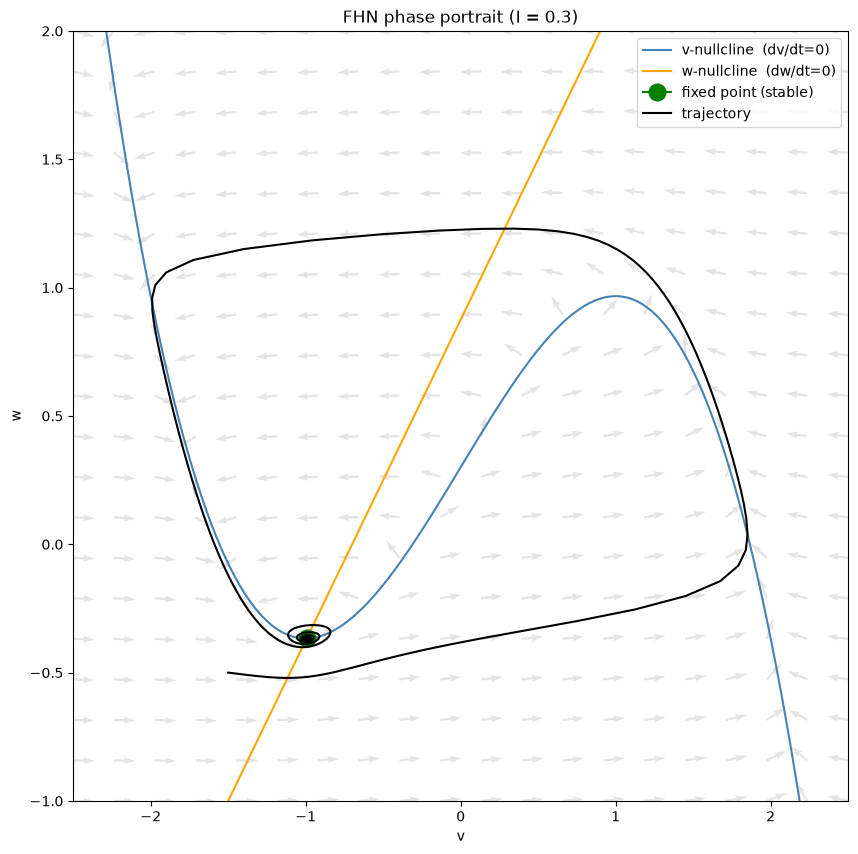

In [160]:
# Section 3: Plots
import matplotlib.pyplot as plt

I_fixed = 0.3
v = np.linspace(-2.5,2.5,500 )
t_array = np.linspace(0,300,1000)

v_grid, w_grid = np.meshgrid(np.linspace(-2.5,2.5,20),np.linspace(-1.0,2.0,20))
derivatives = fhn_derivatives((v_grid, w_grid),v,lambda x: I_fixed)
magnitude = np.sqrt(derivatives[0]**2 + derivatives[1]**2)

fixedpoint = find_fixed_point(I_fixed, a=A_DEFAULT, b=B_DEFAULT)
eigenvalues = jacobian_eigenvalues(fixedpoint[0], a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT)

deriv_func = lambda state,t: fhn_derivatives( state,  t, lambda t: I_fixed, a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT)
results = rk4_integrate(deriv_func, (-1.5,-0.5), t_array)

fig, ax = plt.subplots(1,1, figsize = (10,10))

ax.plot(v, v_nullcline(v, I_fixed), color='steelblue', label='v-nullcline  (dv/dt=0)')
ax.plot(v, w_nullcline(v), color='orange', label='w-nullcline  (dw/dt=0)')

if eigenvalues[0].real < 0 and eigenvalues[1].real < 0:
    ax.plot(fixedpoint[0], fixedpoint[1], marker='o', markersize=12, color='green', label='fixed point (stable)')
else:
    ax.plot(fixedpoint[0], fixedpoint[1], marker='o', markersize=12, color='red', label='fixed point (unstable)')

ax.plot(results[:, 0], results[:, 1], color='black', label='trajectory')

ax.quiver(v_grid, w_grid, derivatives[0]/magnitude, derivatives[1]/magnitude, color='lightgray', alpha = 0.6)
ax.set_title("FHN phase portrait (I = 0.3)")
ax.set_xlabel("v")
ax.set_ylabel("w")
ax.set_ylim((-1,2))
ax.set_xlim((-2.5,2.5))
ax.legend()

plt.show()